<a href="https://colab.research.google.com/github/SakritUser123/DroneHardware/blob/main/Depth_Anything_V2_Small_tester.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [10]:
! git clone https://huggingface.co/spaces/depth-anything/Depth-Anything-V2
%cd Depth-Anything-V2
%pip install -r requirements.txt



fatal: destination path 'Depth-Anything-V2' already exists and is not an empty directory.
/content/Depth-Anything-V2


## Local Inference on GPU
Model page: https://huggingface.co/depth-anything/Depth-Anything-V2-Small

⚠️ If the generated code snippets do not work, please open an issue on either the [model repo](https://huggingface.co/depth-anything/Depth-Anything-V2-Small)
			and/or on [huggingface.js](https://github.com/huggingface/huggingface.js/blob/main/packages/tasks/src/model-libraries-snippets.ts) 🙏

Model loaded


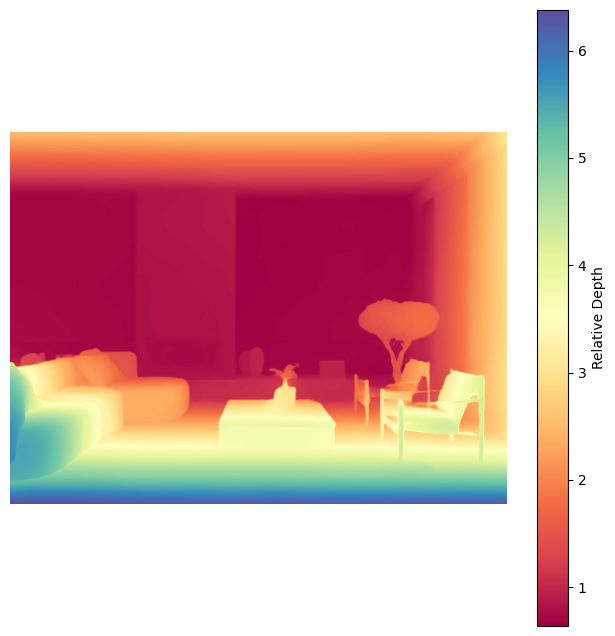

In [24]:

# Install from https://github.com/DepthAnything/Depth-Anything-V2

# Load the model and infer depth from an image
import cv2
import torch
from huggingface_hub import hf_hub_download
from google.colab.patches import cv2_imshow
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"


print("Model loaded")
from depth_anything_v2.dpt import DepthAnythingV2

# instantiate the model
model = DepthAnythingV2(encoder="vits", features=64, out_channels=[48, 96, 192, 384])

# load the weights
filepath = hf_hub_download(repo_id="depth-anything/Depth-Anything-V2-Small", filename="depth_anything_v2_vits.pth", repo_type="model")
state_dict = torch.load(filepath, map_location="cpu")
model.load_state_dict(state_dict)
model.eval()

raw_img = cv2.imread("/content/room.jpg")
model = model.to(DEVICE)

depth = model.infer_image(raw_img) # HxW raw depth map in numpy
import matplotlib.pyplot as plt
plt.figure(figsize=(8,8))
plt.imshow(depth,cmap='Spectral')
plt.colorbar(label="Relative Depth")
plt.axis('off')
plt.show()